# 날씨 음악 V2: 청취 평가 없는 통계 진단

이 노트북은 기존 V2와 제공 CSV의 분포·상관·동점·민감도를 확인하는 재현 자료입니다. 추천 정확도·청취 만족도 검증이 아닙니다. 원본 고유곡89,741개와 유효 분석곡61,931개를 구분합니다. V2 공식과 후보·180분 CSV는 수정하지 않습니다.

## Context & Methods

분석 버전 WEATHER_DIAGNOSTICS_20261016_V1. 분석 출처는 profile_summary.json / sensitivity_summary.json / ../summary.json / 원본 CSV입니다. 음악 특성은 0~1, mode는 범주형0/1 지시변수입니다. 문제군 표본의 플래그를 오류 확률로 해석하지 않습니다. 민감도는 OAT이며 신뢰구간이 아닙니다.


In [1]:
import hashlib, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap

D=Path.cwd()
if not (D/'profile_summary.json').exists():
    D=D/'analysis/weather_music_20261016/diagnostics_20261016'
assert (D/'profile_summary.json').exists(), '분석 폴더에서 실행하거나 저장소 루트에서 실행하세요.'
profile=json.loads((D/'profile_summary.json').read_text(encoding='utf-8'))
sensitivity=json.loads((D/'sensitivity_summary.json').read_text(encoding='utf-8'))
baseline=json.loads((D.parent/'summary.json').read_text(encoding='utf-8'))
source=Path(baseline['source']['path'])
assert hashlib.sha256(source.read_bytes()).hexdigest()==baseline['source']['sha256']
unique=pd.read_csv(source).drop_duplicates('track_id')
weather_codes=list(baseline['weather'])
pool_ids=set()
for weather in weather_codes:
    pool_ids.update(pd.read_csv(D.parent/'pools'/f'{weather}.csv',usecols=['track_id']).track_id)
base=unique[unique.track_id.isin(pool_ids)].copy()
assert len(unique)==89741 and len(base)==61931 and len(pool_ids)==61931
plt.rcParams.update({'font.family':'Malgun Gothic','axes.unicode_minus':False,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.facecolor':'white','axes.labelcolor':'#263238','text.color':'#263238','savefig.facecolor':'white'})
labels={w:baseline['weather'][w]['label'] for w in weather_codes}
print('원본 고유곡:',len(unique),'유효 분석곡:',len(base),'점수 버전:',baseline['policy_version'])
print('원본 SHA-256:',baseline['source']['sha256'])
print(base[['track_id','track_name','energy','acousticness','valence']].sort_values('track_id').head(3).to_string(index=False))


원본 고유곡: 89741 유효 분석곡: 61931 점수 버전: WEATHER_SCORE_PROPOSAL_20261016_V2
원본 SHA-256: b202fa49909b2d5cef71a04b1d21243cfeb36414535f2ca9272aa646721177bd
              track_id                                         track_name  energy  acousticness  valence
000CC8EParg64OmTxVnZ0p It's All Coming Back To Me Now (Glee Cast Version)   0.516       0.40600    0.341
000Iz0K615UepwSJ5z2RE5                      Böxig Leise - Pig & Dan Remix   0.560       0.00114    0.108
000RDCYioLteXcutOjeweY                                         Teeje Week   0.770       0.05830    0.839


## Data: 특성 분포

같은 0~1 구간에서 각 집단의 곡 수로 나눈 구간별 비율입니다. 서로 다른 분모의 빈도수를 직접 비교하지 않습니다. 마지막 구간은1을 포함하며 특성별 세로축 범위는 다릅니다. 원본에 포함된0 등의 값이 모두 음악적으로 유효하다는 뜻은 아닙니다.


     feature     mean    p25   p50   p75  skew_fisher_pearson_unbiased
      energy 0.669854 0.5120 0.712 0.869                     -0.668949
acousticness 0.282835 0.0102 0.131 0.526                      0.865845
     valence 0.487547 0.2700 0.481 0.699                      0.077607


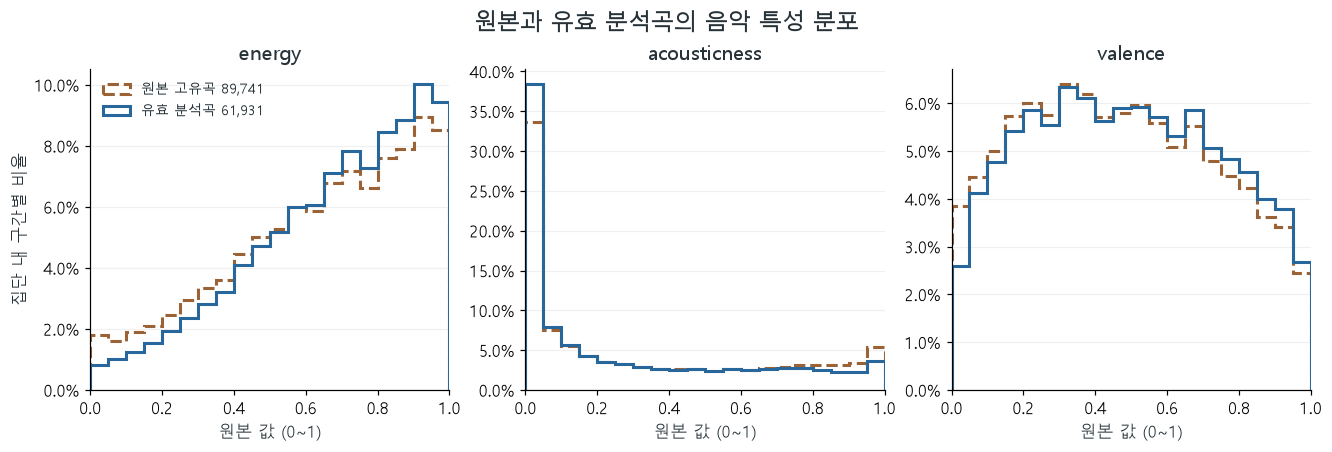

In [2]:
fig,axes=plt.subplots(1,3,figsize=(12,4),layout='constrained')
for ax,feature in zip(axes,['energy','acousticness','valence']):
    for frame,name,color,style in [(unique,'원본 고유곡 89,741','#9a6235','--'),(base,'유효 분석곡 61,931','#27679b','-')]:
        ax.hist(frame[feature],bins=np.linspace(0,1,21),weights=np.full(len(frame),100/len(frame)),histtype='step',linewidth=2,color=color,linestyle=style,label=name)
    ax.set(title=feature,xlim=(0,1),ylim=(0,None),xlabel='원본 값 (0~1)')
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.grid(axis='y',alpha=.18)
axes[0].set_ylabel('집단 내 구간별 비율')
axes[0].legend(fontsize=9,frameon=False)
fig.suptitle('원본과 유효 분석곡의 음악 특성 분포',fontsize=15)
fig.savefig(D/'feature_distributions.png',dpi=150)
plt.show()
plt.close(fig)
print(pd.read_csv(D/'profile_feature_distribution.csv').query("cohort=='BASE_ELIGIBLE_61931' and feature in ['energy','acousticness','valence']") [['feature','mean','p25','p50','p75','skew_fisher_pearson_unbiased']].to_string(index=False))


## Results: 상관과 계수 식별

입력 특성의 관계를 보여주는 Pearson r입니다. weather 정답과의 상관이 아닙니다. mode와 연속 특성의 상관은0/1 지시변수와의 관계입니다. VIF는 입력 중복 진단용 보조 회귀이며 날씨 회귀 계수를 학습한 결과가 아닙니다.


     feature      vif  auxiliary_r_squared
      energy 2.244815             0.554529
acousticness 2.188377             0.543040
     valence 1.070213             0.065607
        mode 1.016378             0.016114


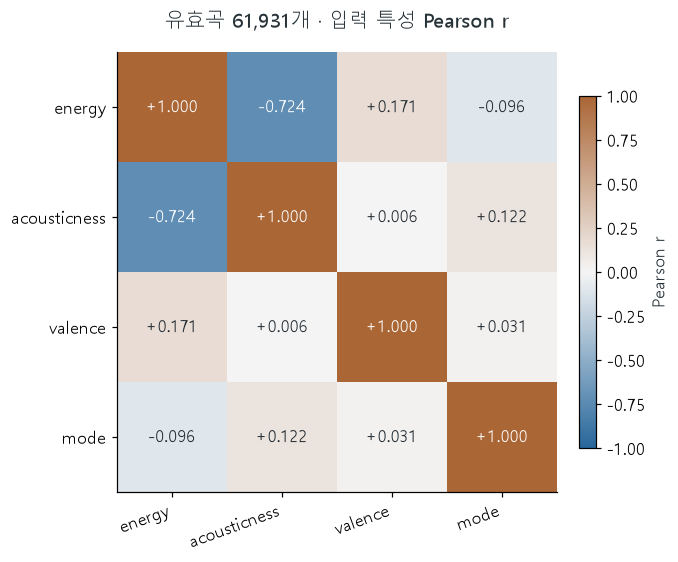

In [3]:
features=['energy','acousticness','valence','mode']
corr=base[features].corr().to_numpy()
fig,ax=plt.subplots(figsize=(6,5),layout='constrained')
im=ax.imshow(corr,vmin=-1,vmax=1,cmap=LinearSegmentedColormap.from_list('signed_blue_brown',['#27679b','#f5f5f5','#aa6635']))
ax.set_xticks(range(4),features,rotation=20,ha='right');ax.set_yticks(range(4),features)
for i in range(4):
    for j in range(4):
        ax.text(j,i,f'{corr[i,j]:+.3f}',ha='center',va='center',color='white' if abs(corr[i,j])>.65 else '#202930')
ax.set_title('유효곡 61,931개 · 입력 특성 Pearson r',pad=16)
fig.colorbar(im,ax=ax,label='Pearson r',shrink=.8)
fig.savefig(D/'feature_correlations.png',dpi=150)
plt.show();plt.close(fig)
print(pd.read_csv(D/'profile_vif.csv').query("cohort=='BASE_ELIGIBLE_61931'")[['feature','vif','auxiliary_r_squared']].to_string(index=False))


## Results: 점수 동점 집중

각 날씨 후보를 분모로 정확76/80/100점과 나머지를 나눴습니다. 같은 곡이 여러 날씨에 포함될 수 있어 날씨 간 곡 수는 합산하지 않습니다. 동점 집중은 순위 세밀함의 한계이며 청취 품질의 낮음이나 높음을 뜻하지 않습니다.


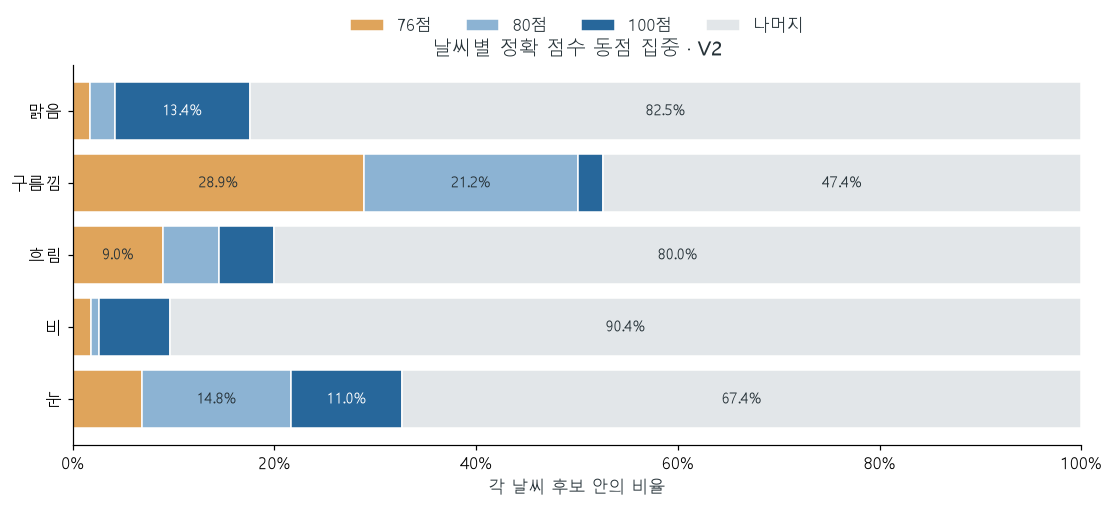

In [4]:
ties=pd.read_csv(D/'profile_pool_score_ties.csv')
ties=ties[ties.selected_kind.eq('ALL')]
fig,ax=plt.subplots(figsize=(10,4.5),layout='constrained')
left=np.zeros(len(weather_codes))
for score,color in [('76','#dfa45b'),('80','#8cb3d3'),('100','#27679b'),('OTHER','#e2e6e9')]:
    vals=[]
    for weather in weather_codes:
        rows=ties[ties.weather.eq(weather)]
        mass={str(r.score_exact):int(r.count) for r in rows.itertuples()}
        n=baseline['weather'][weather]['passing_pool']['track_count']
        vals.append(100*(n-sum(mass.get(k,0) for k in ['76','80','100']) if score=='OTHER' else mass.get(score,0))/n)
    ax.barh([labels[w] for w in weather_codes],vals,left=left,color=color,label='나머지' if score=='OTHER' else score+'점',edgecolor='white')
    for y,(v,x) in enumerate(zip(vals,left)):
        if v>=7: ax.text(x+v/2,y,f'{v:.1f}%',ha='center',va='center',fontsize=10,color='white' if score=='100' else '#263238')
    left+=vals
assert np.allclose(left,100)
ax.set(xlim=(0,100),xlabel='각 날씨 후보 안의 비율',title='날씨별 정확 점수 동점 집중 · V2')
ax.xaxis.set_major_formatter(PercentFormatter(100));ax.invert_yaxis();ax.legend(ncol=4,loc='lower center',bbox_to_anchor=(.5,1.04),frameon=False)
fig.savefig(D/'score_tie_concentration.png',dpi=150)
plt.show();plt.close(fig)


## Results: 하한 민감도

다른 요소는 V2로 고정하고 하한만 바꾼 시나리오입니다. 숫자 사이 실제 간격을 x축에 적용합니다. 전곡 커버는 정책 조건이며 추천 정확도가 아닙니다. 곡선·가중치·h·core의 나머지 시나리오는 sensitivity_summary.json과 CSV에 있습니다.


시나리오 수: 81
모든 시나리오 상위200 동일: True
기존180분 예시 전곡 적격 유지: True


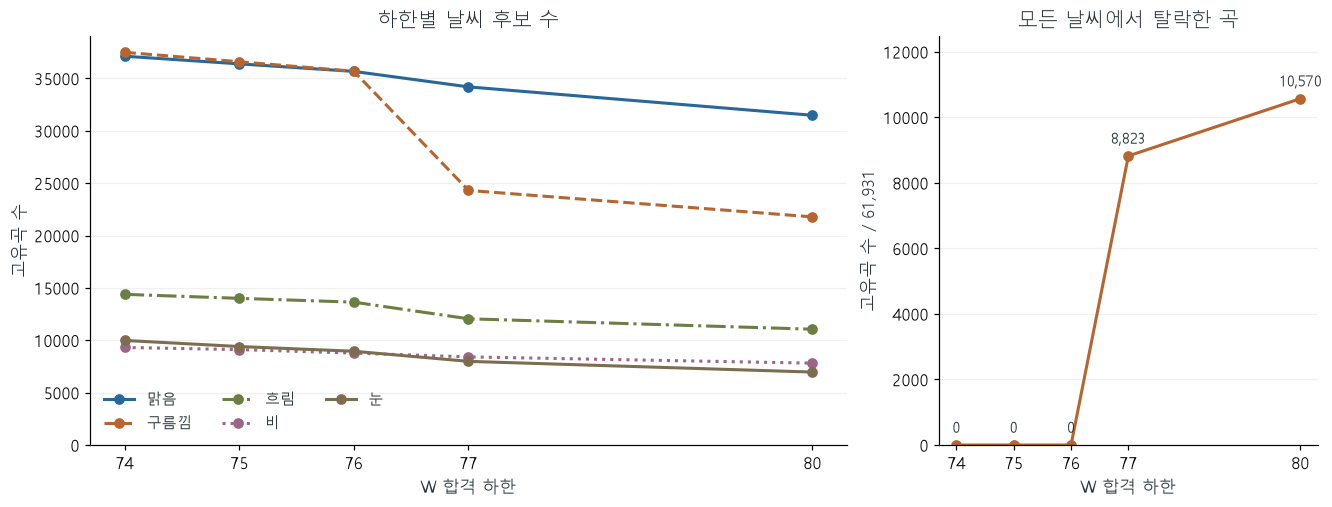

In [5]:
by_threshold={75:sensitivity['scenarios'][0]}
for r in sensitivity['scenarios']:
    if r['configuration']['family']=='threshold': by_threshold[int(r['configuration']['threshold'])]=r
thresholds=sorted(by_threshold)
colors=['#27679b','#b66530','#6b7f43','#9b6686','#7d6d50'];styles=['-','--','-.',':','-']
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained',gridspec_kw={'width_ratios':[2,1]})
for w,color,style in zip(weather_codes,colors,styles):
    axes[0].plot(thresholds,[by_threshold[t]['weather'][w]['pool_count'] for t in thresholds],marker='o',color=color,linestyle=style,label=labels[w],linewidth=2)
axes[0].set(title='하한별 날씨 후보 수',xlabel='W 합격 하한',ylabel='고유곡 수',ylim=(0,None),xticks=thresholds)
axes[0].legend(ncol=3,frameon=False,fontsize=10);axes[0].grid(axis='y',alpha=.18)
missing=[by_threshold[t]['overview']['unmatched_count'] for t in thresholds]
axes[1].plot(thresholds,missing,color='#b66530',marker='o',linewidth=2)
for t,n in zip(thresholds,missing): axes[1].annotate(f'{n:,}',(t,n),xytext=(0,8),textcoords='offset points',ha='center',fontsize=10)
axes[1].set(title='모든 날씨에서 탈락한 곡',xlabel='W 합격 하한',ylabel='고유곡 수 / 61,931',ylim=(0,max(missing)*1.18),xticks=thresholds)
axes[1].grid(axis='y',alpha=.18)
fig.savefig(D/'threshold_sensitivity.png',dpi=150)
plt.show();plt.close(fig)
print('시나리오 수:',sensitivity['scenario_count_including_baseline'])
print('모든 시나리오 상위200 동일:',all(v['top200_retained_count']==200 for r in sensitivity['scenarios'] for v in r['weather'].values()))
print('기존180분 예시 전곡 적격 유지:',all(v['existing_example_all_tracks_still_eligible'] for r in sensitivity['scenarios'] for v in r['weather'].values()))


## Takeaways

- 분포·상관·민감도는 입력과 규칙의 동작을 설명합니다. 청취 정답이 없으므로 정확도 상승을 계산하지 않았습니다.
- 전역 IQR/MAD 표시를 자동 삭제나 LLM 확정값으로 바꾸지 않습니다. 장르별 맥락과 원본 근거를 확인해야 합니다.
- 하한77/80은 전곡 최소한 날씨 조건과 충돌합니다. 상위200 불변은100점 평탄 영역과 동점 처리의 결과입니다.
- 곡선 후보를 바로 채택하지 않고 V2를 보존합니다. LLM은 실제 확보 자료의 보완 초안을 staging에 제안하고 근거·사람 검수를 거치게 설계합니다.

추가 기획서: docs/product/proposals/날씨별_음악_통계진단과_LLM_데이터_보완_추가기획_20261016.md. 실제 API 호출·카탈로그 수정은 하지 않았습니다.
